# EDA: X5 RetailHero uplift

Разведочный анализ обучающей выборки задачи uplift-моделирования X5 RetailHero. Тритмент и таргет бинарные, в тесте таргет не размечен, работаем с трейном.

Данные по товарам (`products.csv`, `product_id`) и магазины (`store_id`) не используются.

In [19]:
# !pip install pandas polars pyarrow numpy matplotlib seaborn scipy statsmodels scikit-learn lightgbm optuna


In [20]:
from pathlib import Path

DATA_DIR = Path('data')
CACHE_DIR = DATA_DIR / 'cache'

CLIENTS_PATH = DATA_DIR / 'clients.csv'
TRAIN_PATH = DATA_DIR / 'uplift_train.csv'
TEST_PATH = DATA_DIR / 'uplift_test.csv'
PURCHASES_PATH = DATA_DIR / 'purchases.csv'

PURCHASE_AGG_PATH = CACHE_DIR / 'client_purchase_agg.parquet'
PURCHASE_META_PATH = CACHE_DIR / 'purchase_agg_meta.json'

RANDOM_STATE = 42
N_CPU = 10
N_TRIALS = 50

INNER_SPLITS = 3
EVAL_SPLITS = 5
TUNE_SIZE = 0.3
N_BOOT_AUC = 1000
ALPHA = 0.05

# Параллелизм Optuna — по trials, внутри модели — свои потоки.
# Произведение не должно сильно превышать N_CPU.
N_JOBS_OPTUNA = max(1, min(8, N_CPU // 2))
N_JOBS_MODEL = max(1, N_CPU // N_JOBS_OPTUNA)

REBUILD_CACHE = False

CONTROL_NAME = 0
TEST_GROUPS = [1]
TREATMENT_COL = 'treatment_flg'
TARGET_COL = 'target'

AGE_MIN = 0
AGE_MAX = 1000
ACTIVITY_WINDOW_DAYS = 30
ANALYTICS_N_ROWS = 50_000

FEATURE_COLUMNS = [
    'age',
    'gender',
    'issue_days',
    'redeem_days',
    'no_redeem',
    'recency_days',
    'n_receipts',
    'purchase_sum',
    'avg_receipt',
    'regular_points_received',
    'express_points_received',
    'regular_points_spent',
    'express_points_spent',
    'activity_share_30d',
]
NUMERIC_FEATURES = [col for col in FEATURE_COLUMNS if col != 'gender']
CATEGORICAL_FEATURES = ['gender']
PRETREATMENT_FEATURES = FEATURE_COLUMNS

# Суммы и счётчики при отсутствии чеков. Давность, средний чек и доля 30 дней не заполняются.
ZERO_IF_NO_PURCHASE = [
    'n_receipts',
    'purchase_sum',
    'regular_points_received',
    'express_points_received',
    'regular_points_spent',
    'express_points_spent',
]


In [21]:
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import polars as pl
import seaborn as sns
from lightgbm import LGBMClassifier
from scipy.stats import chi2_contingency, ttest_ind
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest

optuna.logging.set_verbosity(optuna.logging.WARNING)


# Подготовка данных

Источники: `clients.csv` (анкета и даты карты), `uplift_train.csv` (коммуникация и конверсия), `uplift_test.csv` (только id), `purchases.csv` (история покупок до кампании). Строка покупки — позиция чека.

`purchase_sum`, `regular_points_received`, `express_points_received`, `regular_points_spent`, `express_points_spent` относятся к чеку и повторяются на каждой позиции. Сначала строки схлопываются до `transaction_id`, затем чеки агрегируются до клиента. `trn_sum_from_iss`, `trn_sum_from_red`, `product_quantity`, товар и магазин в признаки не входят.

In [22]:
clients = pd.read_csv(CLIENTS_PATH)
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

clients['first_issue_date'] = pd.to_datetime(clients['first_issue_date'])
clients['first_redeem_date'] = pd.to_datetime(clients['first_redeem_date'])

print('clients', clients.shape)
print('train', train.shape)
print('test', test.shape)
print('treatment_flg:', sorted(train[TREATMENT_COL].dropna().unique().tolist()))
print('target:', sorted(train[TARGET_COL].dropna().unique().tolist()))

display(clients.head())
display(train.head())
display(test.head())


clients (400162, 5)
train (200039, 3)
test (200123, 1)
treatment_flg: [0, 1]
target: [0, 1]


,client_id,first_issue_date,first_redeem_date,age,gender
0,000012768d,2017-08-05 15:40:48,2018-01-04 19:30:07,45,U
1,000036f903,2017-04-10 13:54:23,2017-04-23 12:37:56,72,F
2,000048b7a6,2018-12-15 13:33:11,NaT,68,F
3,000073194a,2017-05-23 12:56:14,2017-11-24 11:18:01,60,F
4,00007c7133,2017-05-22 16:17:08,2018-12-31 17:17:33,67,U


,client_id,treatment_flg,target
0,000012768d,0,1
1,000036f903,1,1
2,00010925a5,1,1
3,0001f552b0,1,1
4,00020e7b18,1,1


,client_id
0,000048b7a6
1,000073194a
2,00007c7133
3,00007f9014
4,0000a90cf7


In [ ]:
cache_ready = (
    PURCHASE_AGG_PATH.exists()
    and PURCHASE_META_PATH.exists()
    and not REBUILD_CACHE
)

if cache_ready:
    print(f'Кеш найден, purchases.csv не сканируется: {PURCHASE_AGG_PATH}')
    purchase_agg = pd.read_parquet(PURCHASE_AGG_PATH)
    purchase_meta = json.loads(PURCHASE_META_PATH.read_text())
    cached_window = purchase_meta.get('activity_window_days')
    if cached_window != ACTIVITY_WINDOW_DAYS:
        print(
            f'В кеше activity_window_days={cached_window}, '
            f'в конфиге {ACTIVITY_WINDOW_DAYS}. '
            'Поставьте REBUILD_CACHE = True, чтобы пересчитать долю активности и давность.'
        )
else:
    print('Сканирую purchases.csv через Polars и собираю кеш по клиентам.')
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    if PURCHASE_AGG_PATH.exists():
        PURCHASE_AGG_PATH.unlink()

    window_days = int(ACTIVITY_WINDOW_DAYS)
    # trn_sum_from_red бывает пустым, поэтому строка. В расчёт колонка не входит.
    schema = {
        'client_id': pl.Utf8,
        'transaction_id': pl.Utf8,
        'transaction_datetime': pl.Utf8,
        'regular_points_received': pl.Float64,
        'express_points_received': pl.Float64,
        'regular_points_spent': pl.Float64,
        'express_points_spent': pl.Float64,
        'purchase_sum': pl.Float64,
        'store_id': pl.Utf8,
        'product_id': pl.Utf8,
        'product_quantity': pl.Float64,
        'trn_sum_from_iss': pl.Float64,
        'trn_sum_from_red': pl.Utf8,
    }
    value_cols = [
        'purchase_sum',
        'regular_points_received',
        'express_points_received',
        'regular_points_spent',
        'express_points_spent',
        'transaction_datetime',
    ]
    aggs = [
        pl.col('client_id').min().alias('client_id_min'),
        pl.col('client_id').max().alias('client_id_max'),
        pl.len().alias('n_lines'),
    ]
    for col in value_cols:
        aggs.append(pl.col(col).min().alias(f'{col}_min'))
        aggs.append(pl.col(col).max().alias(f'{col}_max'))

    tx = (
        pl.scan_csv(str(PURCHASES_PATH), schema=schema, null_values=[''])
        .select([
            'client_id',
            'transaction_id',
            'transaction_datetime',
            'purchase_sum',
            'regular_points_received',
            'express_points_received',
            'regular_points_spent',
            'express_points_spent',
        ])
        .with_columns(
            pl.col('transaction_datetime').str.to_datetime(format='%Y-%m-%d %H:%M:%S')
        )
        .group_by('transaction_id')
        .agg(aggs)
        .collect(engine='streaming')
    )

    def values_conflict(frame, col):
        # eq_missing считает два пропуска равными, поэтому это не конфликт.
        return ~frame[f'{col}_min'].eq_missing(frame[f'{col}_max'])

    client_conflict = values_conflict(tx, 'client_id')
    purchase_sum_conflict = values_conflict(tx, 'purchase_sum')
    points_conflict = values_conflict(tx, 'regular_points_received')
    for col in ('express_points_received', 'regular_points_spent', 'express_points_spent'):
        points_conflict = points_conflict | values_conflict(tx, col)
    dt_conflict = values_conflict(tx, 'transaction_datetime')

    min_dt = tx['transaction_datetime_max'].min()
    max_dt = tx['transaction_datetime_max'].max()
    n_lines = int(tx['n_lines'].sum())
    n_transactions = int(tx.height)
    n_clients = int(tx['client_id_min'].drop_nulls().n_unique())

    window_start = max_dt - pd.Timedelta(days=window_days)
    tx = tx.with_columns(
        pl.col('transaction_datetime_max').ge(window_start).fill_null(False).alias('in_window')
    )
    purchase = (
        tx.group_by('client_id_min')
        .agg(
            pl.len().alias('n_receipts'),
            pl.col('transaction_datetime_max').min().alias('first_purchase_dt'),
            pl.col('transaction_datetime_max').max().alias('last_purchase_dt'),
            pl.col('purchase_sum_max').sum().alias('purchase_sum'),
            pl.col('purchase_sum_max').mean().alias('avg_receipt'),
            pl.col('regular_points_received_max').sum().alias('regular_points_received'),
            pl.col('express_points_received_max').sum().alias('express_points_received'),
            pl.col('regular_points_spent_max').sum().alias('regular_points_spent'),
            pl.col('express_points_spent_max').sum().alias('express_points_spent'),
            pl.col('in_window').sum().alias('n_in_window'),
        )
        .rename({'client_id_min': 'client_id'})
    )
    purchase_agg = purchase.to_pandas()
    purchase_agg['activity_share_30d'] = purchase_agg['n_in_window'] / purchase_agg['n_receipts']
    purchase_agg['recency_days'] = np.floor(
        (pd.Timestamp(max_dt) - purchase_agg['last_purchase_dt']).dt.total_seconds() / 86400.0
    )
    purchase_agg = purchase_agg[[
        'client_id',
        'n_receipts',
        'first_purchase_dt',
        'last_purchase_dt',
        'purchase_sum',
        'avg_receipt',
        'regular_points_received',
        'express_points_received',
        'regular_points_spent',
        'express_points_spent',
        'activity_share_30d',
        'recency_days',
    ]]

    reference_iso = pd.Timestamp(max_dt).isoformat()
    purchase_meta = {
        'min_transaction_datetime': pd.Timestamp(min_dt).isoformat(),
        'max_transaction_datetime': reference_iso,
        'reference_date': reference_iso,
        'n_lines': n_lines,
        'n_transactions': n_transactions,
        'n_clients': n_clients,
        'n_tx_client_conflict': int(client_conflict.sum()),
        'n_tx_purchase_sum_conflict': int(purchase_sum_conflict.sum()),
        'n_tx_points_conflict': int(points_conflict.sum()),
        'n_tx_datetime_conflict': int(dt_conflict.sum()),
        'activity_window_days': window_days,
        'purchases_path': str(PURCHASES_PATH),
    }
    purchase_agg.to_parquet(PURCHASE_AGG_PATH, index=False)
    PURCHASE_META_PATH.write_text(json.dumps(purchase_meta, ensure_ascii=False, indent=2))
    print(f'Кеш записан: {PURCHASE_AGG_PATH}')

print('строк в агрегате:', len(purchase_agg))


Кеш найден, purchases.csv не сканируется: data/cache/client_purchase_agg.parquet
строк в агрегате: 400162
опорная дата: 2019-03-18T23:40:03


## Проверки

Ячейки ниже печатают то, что получилось при прогоне. Числа в выводы заранее не подставлять.


In [24]:
print('min transaction_datetime:', purchase_meta['min_transaction_datetime'])
print('max transaction_datetime:', purchase_meta['max_transaction_datetime'])
print('опорная дата:', purchase_meta['reference_date'])
print('окно активности, суток:', purchase_meta['activity_window_days'])
print('строк позиций:', purchase_meta['n_lines'])
print('чеков:', purchase_meta['n_transactions'])
print('клиентов с покупками:', purchase_meta['n_clients'])
print('чеков с разными client_id:', purchase_meta['n_tx_client_conflict'])
print('чеков с разным purchase_sum:', purchase_meta['n_tx_purchase_sum_conflict'])
print('чеков с разными баллами:', purchase_meta['n_tx_points_conflict'])
print('чеков с разным transaction_datetime:', purchase_meta['n_tx_datetime_conflict'])


min transaction_datetime: 2018-11-21T21:02:33
max transaction_datetime: 2019-03-18T23:40:03
опорная дата: 2019-03-18T23:40:03
окно активности, суток: 30
строк позиций: 45786568
чеков: 8045201
клиентов с покупками: 400162
чеков с разными client_id: 28
чеков с разным purchase_sum: 28
чеков с разными баллами: 27
чеков с разным transaction_datetime: 28


In [25]:
clients_ids = set(clients['client_id'])
train_ids = set(train['client_id'])
test_ids = set(test['client_id'])
purchase_ids = set(purchase_agg['client_id'])

intersection = pd.Series({
    'n_clients': len(clients_ids),
    'n_train': len(train_ids),
    'n_test': len(test_ids),
    'n_purchase_clients': len(purchase_ids),
    'train_and_test': len(train_ids & test_ids),
    'train_not_in_clients': len(train_ids - clients_ids),
    'test_not_in_clients': len(test_ids - clients_ids),
    'purchase_not_in_clients': len(purchase_ids - clients_ids),
    'train_not_in_purchases': len(train_ids - purchase_ids),
    'test_not_in_purchases': len(test_ids - purchase_ids),
    'purchases_not_in_train_or_test': len(purchase_ids - train_ids - test_ids),
    'clients_not_in_train_or_test': len(clients_ids - train_ids - test_ids),
    'train_client_id_duplicates': int(train['client_id'].duplicated().sum()),
    'test_client_id_duplicates': int(test['client_id'].duplicated().sum()),
    'clients_client_id_duplicates': int(clients['client_id'].duplicated().sum()),
})
display(intersection.to_frame('n'))


,n
n_clients,400162
n_train,200039
n_test,200123
n_purchase_clients,400162
train_and_test,0
train_not_in_clients,0
test_not_in_clients,0
purchase_not_in_clients,0
train_not_in_purchases,0
test_not_in_purchases,0


In [26]:
if 'age_raw' not in clients.columns:
    parsed_age = pd.to_numeric(clients['age'], errors='coerce')
    n_non_numeric = int((clients['age'].notna() & parsed_age.isna()).sum())
    print('age не число:', n_non_numeric)
    clients['age_raw'] = parsed_age

age_raw = clients['age_raw']
print(f'age < {AGE_MIN}:', int((age_raw < AGE_MIN).sum()))
print(f'age > {AGE_MAX}:', int((age_raw > AGE_MAX).sum()))
print('age пропуски:', int(age_raw.isna().sum()))
print(
    f'age в (100, {AGE_MAX}] — оставлены как есть:',
    int(((age_raw > 100) & (age_raw <= AGE_MAX)).sum()),
)

invalid_age = (age_raw < AGE_MIN) | (age_raw > AGE_MAX)
clients['age'] = age_raw.mask(invalid_age)
print('age после очистки, пропуски:', int(clients['age'].isna().sum()))


age не число: 0
age < 0: 96
age > 1000: 11
age пропуски: 0
age в (100, 1000] — оставлены как есть: 1038
age после очистки, пропуски: 107


In [27]:
reference_date = pd.Timestamp(purchase_meta['reference_date'])

age_source = (
    clients['age_raw']
    if 'age_raw' in clients.columns
    else pd.to_numeric(clients['age'], errors='coerce')
)
clients_feat = clients.drop(columns=['age_raw'], errors='ignore').copy()
clients_feat['age'] = age_source.mask((age_source < AGE_MIN) | (age_source > AGE_MAX))
clients_feat['issue_days'] = (reference_date - clients_feat['first_issue_date']).dt.days
clients_feat['no_redeem'] = clients_feat['first_redeem_date'].isna().astype(int)
clients_feat['redeem_days'] = (reference_date - clients_feat['first_redeem_date']).dt.days

print('пустой first_issue_date:', int(clients_feat['first_issue_date'].isna().sum()))
print('пустой first_redeem_date:', int(clients_feat['first_redeem_date'].isna().sum()))
print('issue_days < 0:', int((clients_feat['issue_days'] < 0).sum()))
print('redeem_days < 0:', int((clients_feat['redeem_days'] < 0).sum()))

purchase_cols = [
    'client_id',
    'n_receipts',
    'purchase_sum',
    'avg_receipt',
    'regular_points_received',
    'express_points_received',
    'regular_points_spent',
    'express_points_spent',
    'activity_share_30d',
    'recency_days',
]
dataset = train.merge(
    clients_feat[['client_id', 'age', 'gender', 'issue_days', 'redeem_days', 'no_redeem']],
    on='client_id',
    how='left',
).merge(
    purchase_agg[purchase_cols],
    on='client_id',
    how='left',
)

no_purchases = dataset['n_receipts'].isna()
dataset.loc[no_purchases, ZERO_IF_NO_PURCHASE] = 0

dataset = dataset[
    ['client_id', TREATMENT_COL, TARGET_COL] + FEATURE_COLUMNS
]

print('dataset', dataset.shape)
print('train без покупок:', int(no_purchases.sum()))
display(dataset.head())


пустой first_issue_date: 0
пустой first_redeem_date: 35469
issue_days < 0: 0
redeem_days < 0: 44953
dataset (200039, 17)
train без покупок: 0


,client_id,treatment_flg,target,age,gender,issue_days,redeem_days,no_redeem,recency_days,n_receipts,purchase_sum,avg_receipt,regular_points_received,express_points_received,regular_points_spent,express_points_spent,activity_share_30d
0,000012768d,0,1,45.0,U,590,438.0,0,4.0,4,2803.00,700.750000,25.7,0.0,0.0,0.0,0.500000
1,000036f903,1,1,72.0,F,707,694.0,0,1.0,32,9805.00,306.406250,54.9,60.0,0.0,0.0,0.281250
2,00010925a5,1,1,83.0,U,237,185.0,0,10.0,18,5883.00,326.833333,31.8,0.0,-17.0,0.0,0.444444
3,0001f552b0,1,1,33.0,F,626,202.0,0,2.0,15,6155.18,410.345333,78.9,0.0,0.0,0.0,0.466667
4,00020e7b18,1,1,73.0,U,476,432.0,0,3.0,18,25819.61,1434.422778,286.1,0.0,-592.0,-30.0,0.277778


In [28]:
na_table = pd.DataFrame({
    'n_na': dataset.isna().sum(),
    'pct_na': dataset.isna().mean(),
})
display(na_table)

matched_client = dataset['client_id'].isin(set(clients['client_id']))
redeem_mismatch = int((
    (dataset.loc[matched_client, 'no_redeem'] == 1)
    != dataset.loc[matched_client, 'redeem_days'].isna()
).sum())
print('клиентов из clients, где no_redeem=1 не совпадает с пропуском redeem_days:', redeem_mismatch)
print('train без строки в clients:', int((~matched_client).sum()))

no_receipts = dataset['n_receipts'].eq(0)
print('клиентов без чеков:', int(no_receipts.sum()))
if no_receipts.any():
    print('пропуски среди клиентов без чеков:')
    display(
        dataset.loc[no_receipts, ['recency_days', 'avg_receipt', 'activity_share_30d']]
        .isna()
        .sum()
        .to_frame('n_na')
    )
    print('сумма модулей заполненных нулём полей:')
    display(dataset.loc[no_receipts, ZERO_IF_NO_PURCHASE].fillna(0).abs().sum().to_frame('abs_sum'))


,n_na,pct_na
client_id,0,0.000000
treatment_flg,0,0.000000
target,0,0.000000
age,61,0.000305
gender,0,0.000000
issue_days,0,0.000000
redeem_days,17546,0.087713
no_redeem,0,0.000000
recency_days,0,0.000000
n_receipts,0,0.000000


клиентов из clients, где no_redeem=1 не совпадает с пропуском redeem_days: 0
train без строки в clients: 0
клиентов без чеков: 0


**Описание столбцов**

Одна строка `dataset` — клиент из `uplift_train.csv`. Давность считается до опорной даты (максимум `transaction_datetime`).

1. `treatment_flg` — 1, если была коммуникация, 0 — контроль.
2. `target` — конверсия после кампании.
3. `age` — возраст. Значения `< 0` и `> 1000` заменены на пропуск. Возраст от 101 до 1000 не менялся.
4. `gender` — пол: M, F или U.
5. `issue_days` — полных суток от `first_issue_date` до опорной даты.
6. `redeem_days` — полных суток от `first_redeem_date` до опорной даты. Пропуск, если списания не было.
7. `no_redeem` — 1, если `first_redeem_date` пустой, иначе 0.
8. `recency_days` — полных суток от последнего чека клиента до опорной даты. Пропуск, если чеков не было.
9. `n_receipts` — число чеков. 0, если покупок не было.
10. `purchase_sum` — сумма чеков после схлопывания позиций. 0, если покупок не было.
11. `avg_receipt` — средний чек. Пропуск, если покупок не было. Линейно связан с суммой и числом чеков.
12. `regular_points_received` — сумма начисленных regular-баллов по чекам. 0, если покупок не было.
13. `express_points_received` — сумма начисленных express-баллов по чекам. 0, если покупок не было.
14. `regular_points_spent` — сумма списанных regular-баллов по чекам. 0, если покупок не было.
15. `express_points_spent` — сумма списанных express-баллов по чекам. 0, если покупок не было.
16. `activity_share_30d` — доля чеков клиента за последние 30 суток до опорной даты. Пропуск, если чеков не было.

`client_id` оставлен для проверок и в модель не идёт. `no_redeem` дальше считается числовым признаком (0/1), `gender` — категориальным.


In [29]:
# Покупки уже посчитаны по всей истории. Здесь режется только число клиентов в EDA.
n_full = len(dataset)
if n_full > ANALYTICS_N_ROWS:
    strata = dataset[TREATMENT_COL].astype(str) + '_' + dataset[TARGET_COL].astype(str)
    dataset, _ = train_test_split(
        dataset,
        train_size=ANALYTICS_N_ROWS,
        stratify=strata,
        random_state=RANDOM_STATE,
    )
    dataset = dataset.reset_index(drop=True)
print(f'клиентов в аналитике: {len(dataset)} из {n_full}')


клиентов в аналитике: 50000 из 200039


# EDA


## Базовый просмотр (пропуски, дубликаты)


In [30]:
dataset.info()


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   client_id                50000 non-null  str    
 1   treatment_flg            50000 non-null  int64  
 2   target                   50000 non-null  int64  
 3   age                      49989 non-null  float64
 4   gender                   50000 non-null  str    
 5   issue_days               50000 non-null  int64  
 6   redeem_days              45622 non-null  float64
 7   no_redeem                50000 non-null  int64  
 8   recency_days             50000 non-null  float64
 9   n_receipts               50000 non-null  uint32 
 10  purchase_sum             50000 non-null  float64
 11  avg_receipt              50000 non-null  float64
 12  regular_points_received  50000 non-null  float64
 13  express_points_received  50000 non-null  float64
 14  regular_points_spent     50000 no

In [31]:
dataset.describe()


,treatment_flg,target,age,issue_days,redeem_days,no_redeem,recency_days,n_receipts,purchase_sum,avg_receipt,regular_points_received,express_points_received,regular_points_spent,express_points_spent,activity_share_30d
count,50000.000000,50000.000000,49989.000000,50000.000000,45622.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.00000,50000.000000
mean,0.499800,0.619880,46.766489,433.311280,265.368441,0.087560,5.840800,20.077560,8590.731518,496.271524,78.002622,0.77880,-72.947540,-6.38366,0.360574
std,0.500005,0.485421,23.629093,204.080416,218.998587,0.282657,5.665762,17.648297,8975.213883,374.137155,97.054661,7.54252,130.298516,16.29340,0.214968
min,0.000000,0.000000,0.000000,3.000000,-247.000000,0.000000,0.000000,1.000000,1.040000,1.040000,0.000000,0.00000,-5849.000000,-330.00000,0.013333
25%,0.000000,0.000000,33.000000,270.000000,72.000000,0.000000,1.000000,8.000000,3148.435000,260.401667,23.400000,0.00000,-98.000000,0.00000,0.222222
50%,0.000000,1.000000,45.000000,488.000000,288.000000,0.000000,4.000000,15.000000,6087.420000,394.417045,49.400000,0.00000,-26.000000,0.00000,0.304348
75%,1.000000,1.000000,59.000000,605.000000,449.000000,0.000000,9.000000,27.000000,11088.467500,609.973333,96.800000,0.00000,0.000000,0.00000,0.428571
max,1.000000,1.000000,980.000000,707.000000,702.000000,1.000000,22.000000,248.000000,459562.910000,7120.590000,4526.700000,300.00000,0.000000,0.00000,1.000000


In [32]:
print('полных дублей строк:', int(dataset.duplicated().sum()))
print('дублей client_id:', int(dataset['client_id'].duplicated().sum()))


полных дублей строк: 0
дублей client_id: 0


**Базовый просмотр**

Графики, тесты и модель ниже посчитаны на подвыборке 50 000 из 200 039 клиентов train. Пропуски ниже относятся к полному train: эта проверка выполнена до подвыборки.

- Конверсия: `target = 1` у 61.99% подвыборки, медиана равна 1, нижний квартиль 0.
- Полных дублей строк 0, дублей `client_id` 0.
- На полном train пустые только `age` (61, 0.03%) и `redeem_days` (17 546, 8.77%). Пропуск `redeem_days` совпадает с `no_redeem = 1`. Клиентов без чеков нет, поэтому `recency_days`, `avg_receipt` и `activity_share_30d` без пропусков. В подвыборке `redeem_days` доходит до -247: часть первых списаний позже опорной даты 2019-03-18.


## Анализ эффектов и сбалансированности


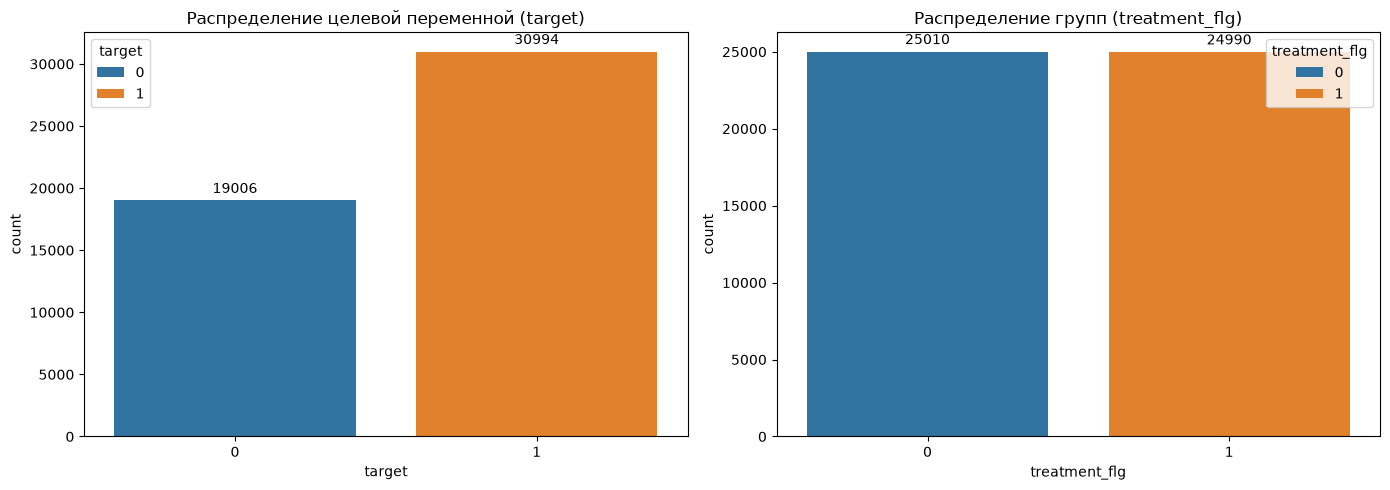

Доля конверсии (target=1): 61.988%
Доли treatment_flg


treatment_flg
0    0.5002
1    0.4998
Name: proportion, dtype: float64

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x=TARGET_COL, data=dataset, ax=ax[0], hue=TARGET_COL)
ax[0].set_title('Распределение целевой переменной (target)')
for container in ax[0].containers:
    ax[0].bar_label(container, padding=3)

sns.countplot(x=TREATMENT_COL, data=dataset, ax=ax[1], hue=TREATMENT_COL)
ax[1].set_title('Распределение групп (treatment_flg)')
for container in ax[1].containers:
    ax[1].bar_label(container, padding=3)

plt.tight_layout()
plt.show()

print(f"Доля конверсии (target=1): {dataset[TARGET_COL].mean():.3%}")
print('Доли treatment_flg')
display(dataset[TREATMENT_COL].value_counts(normalize=True))


In [34]:
def build_uplift_ztest_table(df, target_col, treatment_col, control_name):
    # Метрики на контроле
    control_df = df[df[treatment_col] == control_name]
    n_control = len(control_df)
    conv_control = control_df[target_col].mean()
    success_control = control_df[target_col].sum()

    test_groups = [t for t in df[treatment_col].unique() if t != control_name]
    results = []

    # Z-тест каждой тестовой группы против контроля
    for test_name in test_groups:
        test_df = df[df[treatment_col] == test_name]
        n_test = len(test_df)
        conv_test = test_df[target_col].mean()
        success_test = test_df[target_col].sum()

        count = np.array([success_test, success_control])
        nobs = np.array([n_test, n_control])
        stat, pval = proportions_ztest(count, nobs)

        results.append({
            'Compare': f'{test_name} vs {control_name}',
            'N_test': n_test,
            'N_control': n_control,
            'Conv_test': conv_test * 100,
            'Conv_control': conv_control * 100,
            'absolute effect': (conv_test - conv_control) * 100,
            'z_stat': stat,
            'p_value_raw': pval,
        })

    res_df = pd.DataFrame(results)

    # Поправка на множественное тестирование. При одной группе Holm совпадает с сырым p-value.
    reject, pvals_corrected, _, _ = multipletests(res_df['p_value_raw'], alpha=0.05, method='holm')
    res_df['p_value_holm'] = pvals_corrected
    res_df['is_significant'] = reject

    res_df['Conv_test'] = res_df['Conv_test'].round(2).astype(str) + '%'
    res_df['Conv_control'] = res_df['Conv_control'].round(2).astype(str) + '%'
    res_df['absolute effect'] = res_df['absolute effect'].round(2).astype(str) + '%'
    res_df['z_stat'] = res_df['z_stat'].round(3)
    res_df['p_value_raw'] = res_df['p_value_raw'].apply(lambda x: f'{x:.2e}')
    res_df['p_value_holm'] = res_df['p_value_holm'].apply(lambda x: f'{x:.2e}')
    return res_df


table_conversion = build_uplift_ztest_table(
    dataset,
    target_col=TARGET_COL,
    treatment_col=TREATMENT_COL,
    control_name=CONTROL_NAME,
)
display(table_conversion)


,Compare,N_test,N_control,Conv_test,Conv_control,absolute effect,z_stat,p_value_raw,p_value_holm,is_significant
0,1 vs 0,24990,25010,63.65%,60.33%,3.32%,7.65,2.00e-14,2.00e-14,True


### Баланс числовых фичей


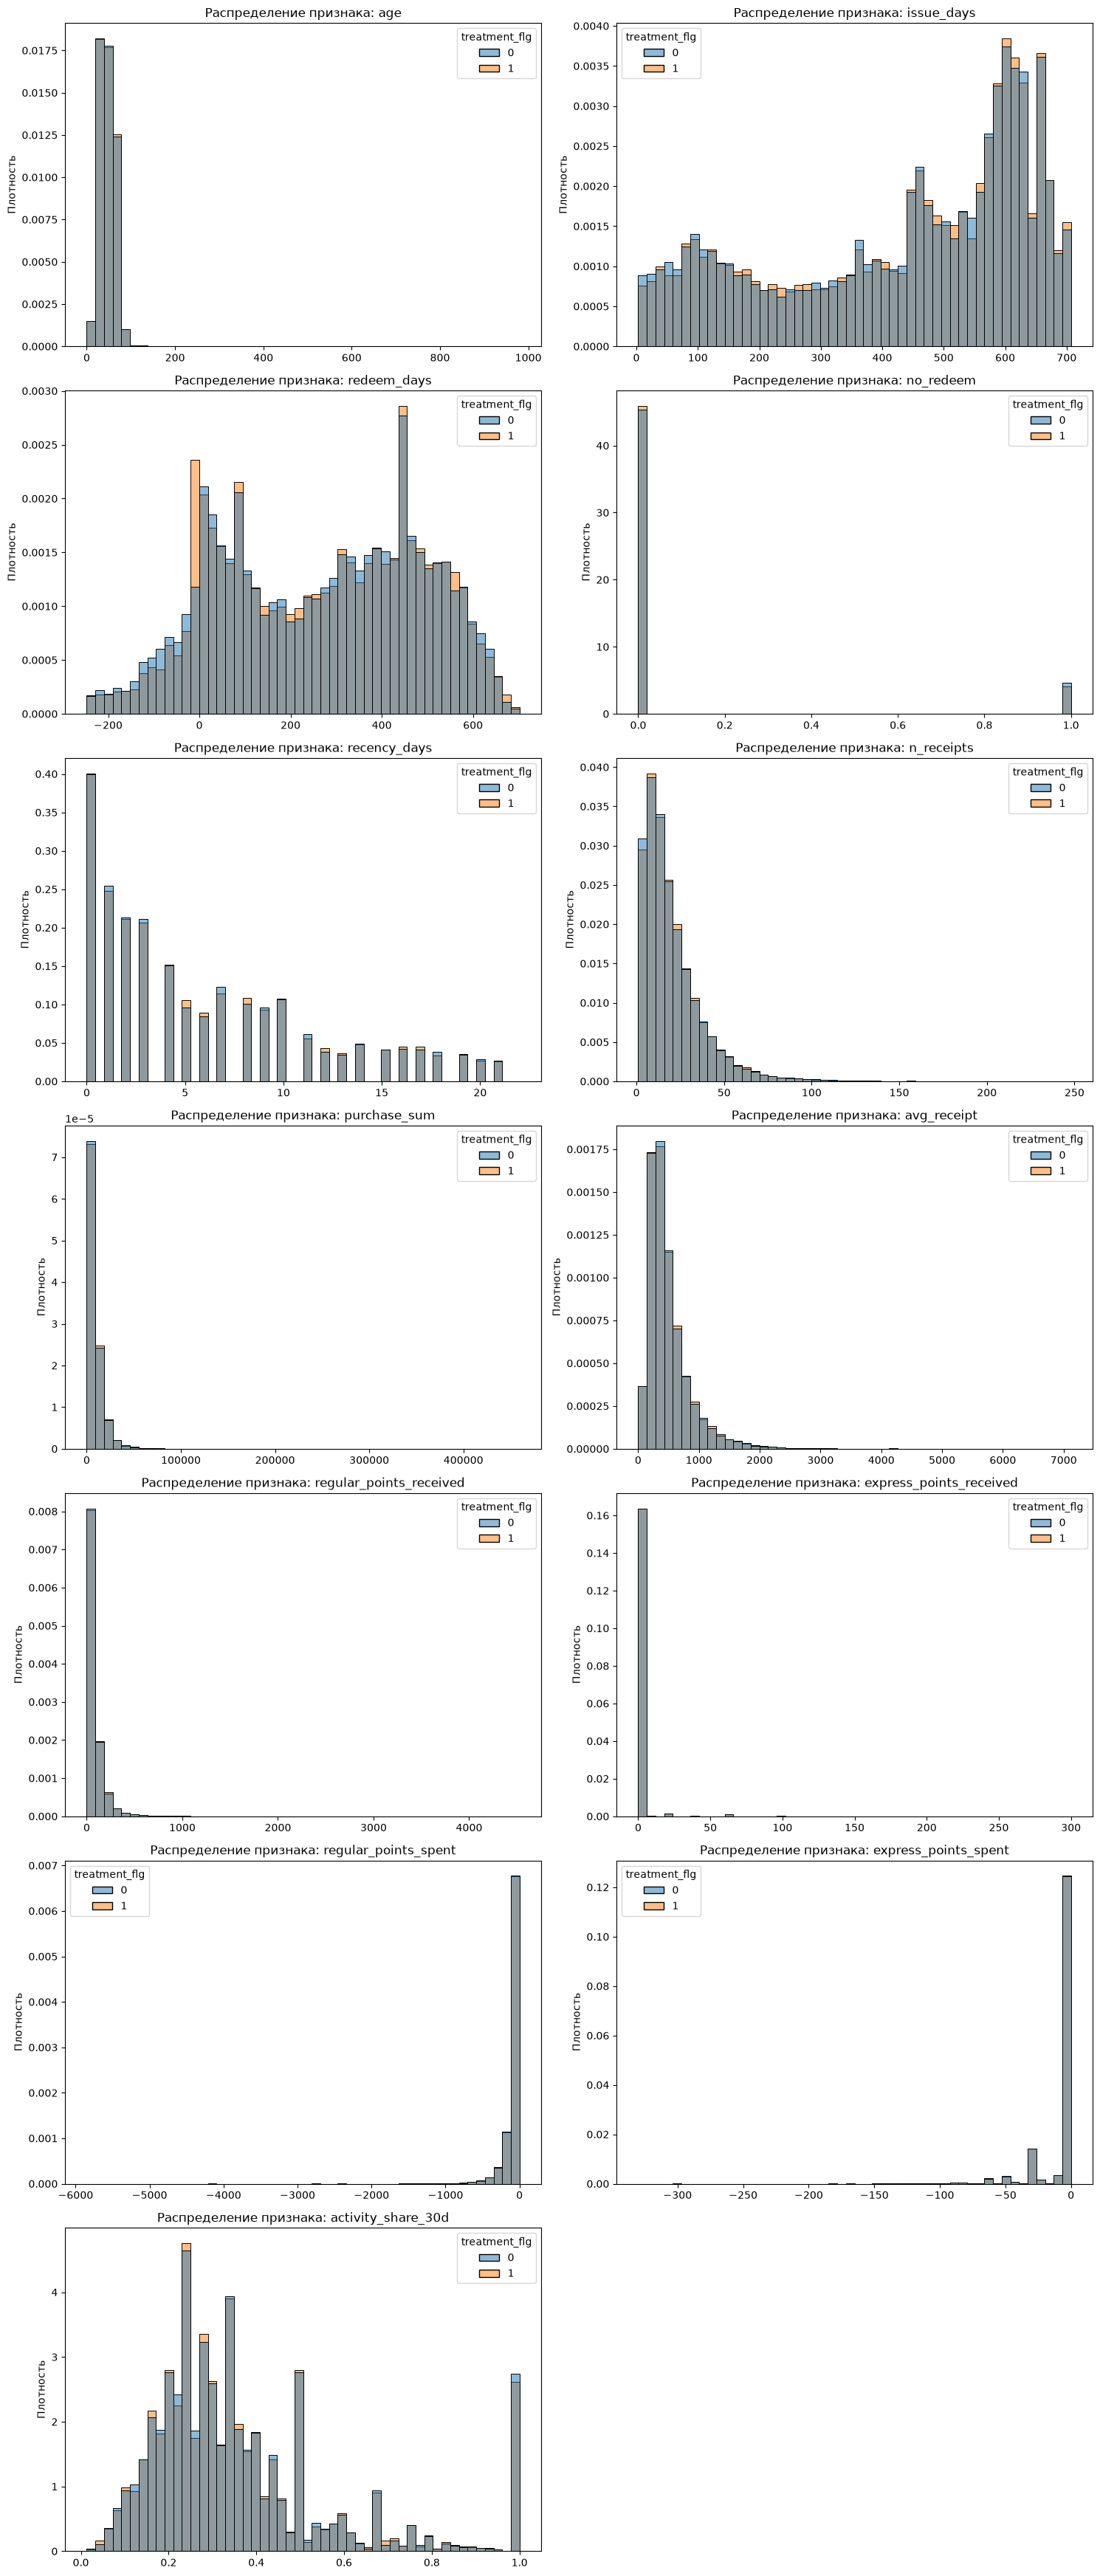

,Feature,Compare,Mean_Test,Mean_Control,SMD,T_Stat,P_Value,Is_Significant
12,activity_share_30d,1 vs 0,0.360,0.361,0.0023,-0.262,7.93e-01,False
0,age,1 vs 0,46.745,46.788,0.0018,-0.204,8.38e-01,False
7,avg_receipt,1 vs 0,498.018,494.526,0.0093,1.044,2.97e-01,False
9,express_points_received,1 vs 0,0.748,0.809,0.0081,-0.910,3.63e-01,False
11,express_points_spent,1 vs 0,-6.355,-6.412,0.0035,0.390,6.96e-01,False
1,issue_days,1 vs 0,434.768,431.856,0.0143,1.595,1.11e-01,False
5,n_receipts,1 vs 0,20.168,19.987,0.0102,1.143,2.53e-01,False
3,no_redeem,1 vs 0,0.082,0.093,0.0380,-4.245,2.19e-05,True
6,purchase_sum,1 vs 0,8635.512,8545.987,0.0100,1.115,2.65e-01,False
4,recency_days,1 vs 0,5.847,5.835,0.0022,0.244,8.07e-01,False


In [35]:
def analyze_numeric_balance(df, treatment_col, numeric_cols, control_name):
    # Гистограммы
    n_cols = len(numeric_cols)
    n_rows = (n_cols + 1) // 2

    fig, axes = plt.subplots(n_rows, 2, figsize=(15, 5 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    for i, col in enumerate(numeric_cols):
        ax = axes[i]
        sns.histplot(
            data=df,
            x=col,
            hue=treatment_col,
            alpha=0.5,
            ax=ax,
            stat='density',
            common_norm=False,
            bins=50,
        )
        ax.set_title(f'Распределение признака: {col}', fontsize=12)
        ax.set_ylabel('Плотность')
        ax.set_xlabel('')

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

    # SMD и Welch t-test
    results = []
    control_df = df[df[treatment_col] == control_name]
    test_groups = [t for t in df[treatment_col].unique() if t != control_name]

    for group in test_groups:
        test_df = df[df[treatment_col] == group]
        for col in numeric_cols:
            x_test = test_df[col].dropna()
            x_control = control_df[col].dropna()

            if len(x_test) < 2 or len(x_control) < 2:
                mean_t = x_test.mean() if len(x_test) else np.nan
                mean_c = x_control.mean() if len(x_control) else np.nan
                smd = np.nan
                t_stat, p_val = np.nan, np.nan
            else:
                mean_t = x_test.mean()
                mean_c = x_control.mean()
                var_t = x_test.var(ddof=1)
                var_c = x_control.var(ddof=1)
                denom = np.sqrt((var_t + var_c) / 2)
                smd = (mean_t - mean_c) / denom if denom > 0 else np.nan
                t_stat, p_val = ttest_ind(x_test, x_control, equal_var=False)

            results.append({
                'Feature': col,
                'Compare': f'{group} vs {control_name}',
                'Mean_Test': mean_t,
                'Mean_Control': mean_c,
                'SMD': abs(smd),
                'T_Stat': t_stat,
                'P_Value': p_val,
                'Is_Significant': bool(p_val < 0.05) if pd.notna(p_val) else False,
            })

    balance_df = pd.DataFrame(results)
    balance_df['Mean_Test'] = balance_df['Mean_Test'].round(3)
    balance_df['Mean_Control'] = balance_df['Mean_Control'].round(3)
    balance_df['SMD'] = balance_df['SMD'].round(4)
    balance_df['T_Stat'] = balance_df['T_Stat'].round(3)
    balance_df['P_Value'] = balance_df['P_Value'].apply(lambda x: f'{x:.2e}')
    return balance_df.sort_values(by=['Compare', 'Feature'])


balance_table = analyze_numeric_balance(
    dataset,
    treatment_col=TREATMENT_COL,
    numeric_cols=NUMERIC_FEATURES,
    control_name=CONTROL_NAME,
)
display(balance_table)


### Баланс категориальных фичей


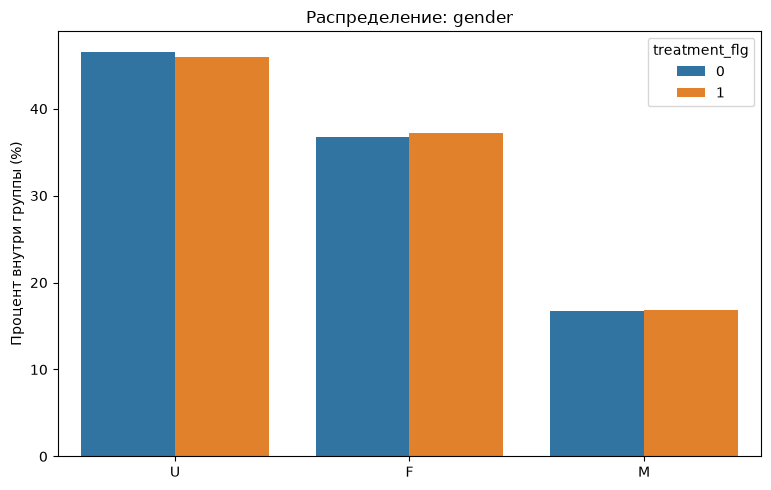

,Feature,Compare,Chi2_Stat,P_Value,Cramers_V,Is_Significant
0,gender,1 vs 0,1.756,4.16e-01,0.0059,False


In [36]:
def analyze_categorical_balance(df, treatment_col, categorical_cols, control_name):
    # Столбчатые диаграммы долей внутри группы
    n_cols = len(categorical_cols)
    n_rows = (n_cols + 1) // 2

    fig, axes = plt.subplots(n_rows, 2, figsize=(15, 5 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    for i, col in enumerate(categorical_cols):
        ax = axes[i]
        share = (
            df.groupby(treatment_col)[col]
            .value_counts(normalize=True)
            .mul(100)
            .rename('percent')
            .reset_index()
        )
        sns.barplot(data=share, x=col, y='percent', hue=treatment_col, ax=ax)
        ax.set_title(f'Распределение: {col}', fontsize=12)
        ax.set_ylabel('Процент внутри группы (%)')
        ax.set_xlabel('')
        if df[col].nunique(dropna=True) > 4:
            ax.tick_params(axis='x', rotation=45)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

    # Хи-квадрат и Cramer's V
    results = []
    test_groups = [t for t in df[treatment_col].unique() if t != control_name]

    for group in test_groups:
        subset_df = df[df[treatment_col].isin([group, control_name])]
        for col in categorical_cols:
            contingency_table = pd.crosstab(subset_df[col], subset_df[treatment_col])
            chi2, p_val, _, _ = chi2_contingency(contingency_table)
            n = contingency_table.sum().sum()
            min_dim = min(contingency_table.shape) - 1
            cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 and n > 0 else 0

            results.append({
                'Feature': col,
                'Compare': f'{group} vs {control_name}',
                'Chi2_Stat': chi2,
                'P_Value': p_val,
                'Cramers_V': abs(cramers_v),
                'Is_Significant': p_val < 0.05,
            })

    balance_df = pd.DataFrame(results)
    balance_df['Chi2_Stat'] = balance_df['Chi2_Stat'].round(3)
    balance_df['P_Value'] = balance_df['P_Value'].apply(lambda x: f'{x:.2e}')
    balance_df['Cramers_V'] = balance_df['Cramers_V'].round(4)
    return balance_df


cat_balance_table = analyze_categorical_balance(
    dataset,
    treatment_col=TREATMENT_COL,
    categorical_cols=CATEGORICAL_FEATURES,
    control_name=CONTROL_NAME,
)
display(cat_balance_table)


## Проверка случайности назначения treatment

SMD и хи-квадрат смотрят на признаки по одному и не увидят зависимость, спрятанную во взаимодействиях. Поэтому решается обратная задача: по предтритментным признакам предсказывается принадлежность к тестовой группе (`treatment_flg = 1` против контроля `0`). Если назначение было случайным, предсказать его невозможно и ROC AUC должен быть неотличим от 0.5.

Гиперпараметры LightGBM подбираются Optuna на тюнинговой части (`TUNE_SIZE` строк, `N_TRIALS` попыток, `INNER_SPLITS` фолдов). OOF AUC и бутстрап 95% ДИ считаются на оставшейся части с уже зафиксированными параметрами: тюнинг и оценка не пересекаются. Пропуски не заполняются, LightGBM принимает их сам. `gender` кодируется dummy-переменными.


In [37]:
BOOSTER = 'lightgbm'


def make_xy(df, test_name, control_name=CONTROL_NAME):
    sub = df[df[TREATMENT_COL].isin([test_name, control_name])]
    X = pd.get_dummies(
        sub[PRETREATMENT_FEATURES],
        columns=CATEGORICAL_FEATURES,
        drop_first=True,
        dtype=float,
    ).reset_index(drop=True)
    X.columns = [re.sub(r'[^0-9A-Za-z_]+', '_', str(c)).strip('_') for c in X.columns]
    y = (sub[TREATMENT_COL] == test_name).astype(int).to_numpy()
    return X, y


def make_model(params, n_jobs=N_JOBS_MODEL):
    if BOOSTER == 'lightgbm':
        return LGBMClassifier(
            random_state=RANDOM_STATE,
            n_jobs=n_jobs,
            verbose=-1,
            subsample_freq=1,
            **params,
        )
    raise ValueError(f'Неизвестный BOOSTER: {BOOSTER}')


def suggest_params(trial):
    return dict(
        n_estimators=trial.suggest_int('n_estimators', 100, 400, step=50),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        num_leaves=trial.suggest_int('num_leaves', 7, 63),
        max_depth=trial.suggest_int('max_depth', 2, 8),
        min_child_samples=trial.suggest_int('min_child_samples', 20, 300),
        subsample=trial.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
    )


def cv_auc(X, y, params, n_splits=INNER_SPLITS, seed=RANDOM_STATE, n_jobs_model=N_JOBS_MODEL):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = []
    for tr, va in skf.split(X, y):
        model = make_model(params, n_jobs=n_jobs_model)
        model.fit(X.iloc[tr], y[tr])
        scores.append(roc_auc_score(y[va], model.predict_proba(X.iloc[va])[:, 1]))
    return float(np.mean(scores))


In [38]:
def tune_params(X, y, n_trials=N_TRIALS, inner_splits=INNER_SPLITS, seed=RANDOM_STATE):
    """Подбор гиперпараметров Optuna на тюнинговой части выборки.
    Параллелизм — по trials."""
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=seed),
    )
    study.optimize(
        lambda t: cv_auc(X, y, suggest_params(t), n_splits=inner_splits, seed=seed),
        n_trials=n_trials,
        n_jobs=N_JOBS_OPTUNA,
        show_progress_bar=False,
    )
    return study.best_params, float(study.best_value)


print(
    f'Optuna n_jobs={N_JOBS_OPTUNA}, LightGBM n_jobs={N_JOBS_MODEL}, '
    f'trials={N_TRIALS}'
)

randomization = {}

for test_group in TEST_GROUPS:
    X, y = make_xy(dataset, test_group)

    # Тюнинговая и оценочная части не пересекаются: гиперпараметры выбираются по
    # настоящим меткам, поэтому оценивать AUC на тех же данных нельзя.
    X_tune, X_eval, y_tune, y_eval = train_test_split(
        X, y, train_size=TUNE_SIZE, stratify=y, random_state=RANDOM_STATE,
    )
    X_eval = X_eval.reset_index(drop=True)

    best_params, best_inner_auc = tune_params(X_tune.reset_index(drop=True), y_tune)

    randomization[test_group] = {
        'X_eval': X_eval,
        'y_eval': y_eval,
        'params': best_params,
        'tune_auc': best_inner_auc,
    }
    print(
        f'{test_group} vs {CONTROL_NAME}: n_tune={len(y_tune)}, n_eval={len(y_eval)}, '
        f'лучший AUC на тюнинговой части={best_inner_auc:.4f}'
    )
    print('  params:', best_params)


Optuna n_jobs=5, LightGBM n_jobs=2, trials=50
1 vs 0: n_tune=15000, n_eval=35000, лучший AUC на тюнинговой части=0.5178
  params: {'n_estimators': 100, 'learning_rate': 0.06237487925623128, 'num_leaves': 53, 'max_depth': 5, 'min_child_samples': 294, 'subsample': 0.6328995238975058, 'colsample_bytree': 0.8233571811162782, 'reg_lambda': 3.8787548668137926}


,Compare,N_eval,AUC,CI_95_low,CI_95_high,CI_covers_0.5
0,1 vs 0,35000,0.5203,0.5145,0.5269,False


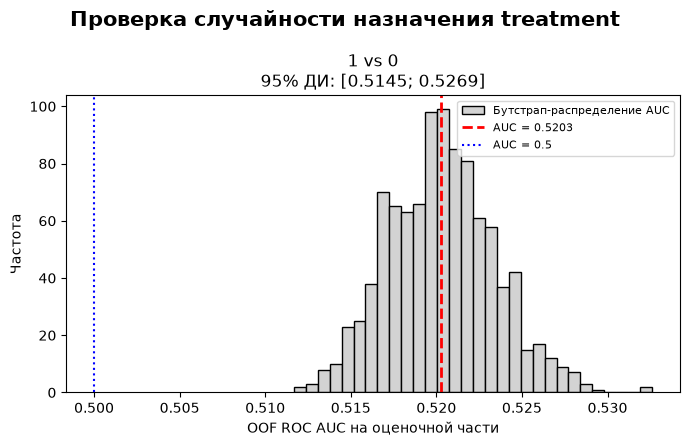

In [39]:
def oof_auc_fixed(X, y, params, n_splits=EVAL_SPLITS, seed=RANDOM_STATE, n_jobs_model=N_JOBS_MODEL):
    """OOF AUC на оценочной части с фиксированными гиперпараметрами."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.full(len(y), np.nan)
    for tr, te in skf.split(X, y):
        model = make_model(params, n_jobs=n_jobs_model)
        model.fit(X.iloc[tr], y[tr])
        oof[te] = model.predict_proba(X.iloc[te])[:, 1]
    return float(roc_auc_score(y, oof)), oof


def bootstrap_auc_ci(y, scores, n_boot=N_BOOT_AUC, alpha=ALPHA, seed=RANDOM_STATE):
    """Перцентильный бутстрап AUC. Ресэмпл стратифицирован по классу, чтобы в
    каждой итерации сохранялся размер обеих групп. Интервал учитывает разброс
    самой метрики на этой выборке, но не разброс обучения модели."""
    rng = np.random.default_rng(seed)
    idx_pos = np.flatnonzero(y == 1)
    idx_neg = np.flatnonzero(y == 0)
    aucs = np.empty(n_boot)
    for b in range(n_boot):
        idx = np.concatenate([
            rng.choice(idx_pos, idx_pos.size, replace=True),
            rng.choice(idx_neg, idx_neg.size, replace=True),
        ])
        aucs[b] = roc_auc_score(y[idx], scores[idx])
    lo, hi = np.quantile(aucs, [alpha / 2, 1 - alpha / 2])
    return float(lo), float(hi), aucs


rows = []

for test_group, res in randomization.items():
    auc_obs, oof = oof_auc_fixed(res['X_eval'], res['y_eval'], res['params'])
    lo, hi, boot_aucs = bootstrap_auc_ci(res['y_eval'], oof)

    res.update({'auc': auc_obs, 'oof': oof, 'ci': (lo, hi), 'boot_aucs': boot_aucs})

    rows.append({
        'Compare': f'{test_group} vs {CONTROL_NAME}',
        'N_eval': len(res['y_eval']),
        'AUC': round(auc_obs, 4),
        'CI_95_low': round(lo, 4),
        'CI_95_high': round(hi, 4),
        'CI_covers_0.5': bool(lo <= 0.5 <= hi),
    })

randomization_table = pd.DataFrame(rows)
display(randomization_table)

fig, axes = plt.subplots(1, len(randomization), figsize=(7 * len(randomization), 4.5), squeeze=False)
for ax, (test_group, res) in zip(axes[0], randomization.items()):
    ax.hist(
        res['boot_aucs'],
        bins=30,
        color='lightgrey',
        edgecolor='black',
        label='Бутстрап-распределение AUC',
    )
    ax.axvline(
        res['auc'],
        color='red',
        linestyle='--',
        linewidth=2,
        label=f"AUC = {res['auc']:.4f}",
    )
    ax.axvline(0.5, color='blue', linestyle=':', linewidth=1.5, label='AUC = 0.5')
    ax.set_title(
        f'{test_group} vs {CONTROL_NAME}\n'
        f'95% ДИ: [{res["ci"][0]:.4f}; {res["ci"][1]:.4f}]'
    )
    ax.set_xlabel('OOF ROC AUC на оценочной части')
    ax.set_ylabel('Частота')
    ax.legend(fontsize=8)
plt.suptitle('Проверка случайности назначения treatment', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


**Случайность treatment**

OOF ROC AUC модели, которая предсказывает `treatment_flg`, на 35 000 клиентов оценочной части равен 0.5203. 95% бутстрап-интервал [0.5145; 0.5269] не накрывает 0.5: признаки отличают тест от контроля лучше случайного угадывания, но отрыв небольшой.


## Анализ влияния фичей на таргет


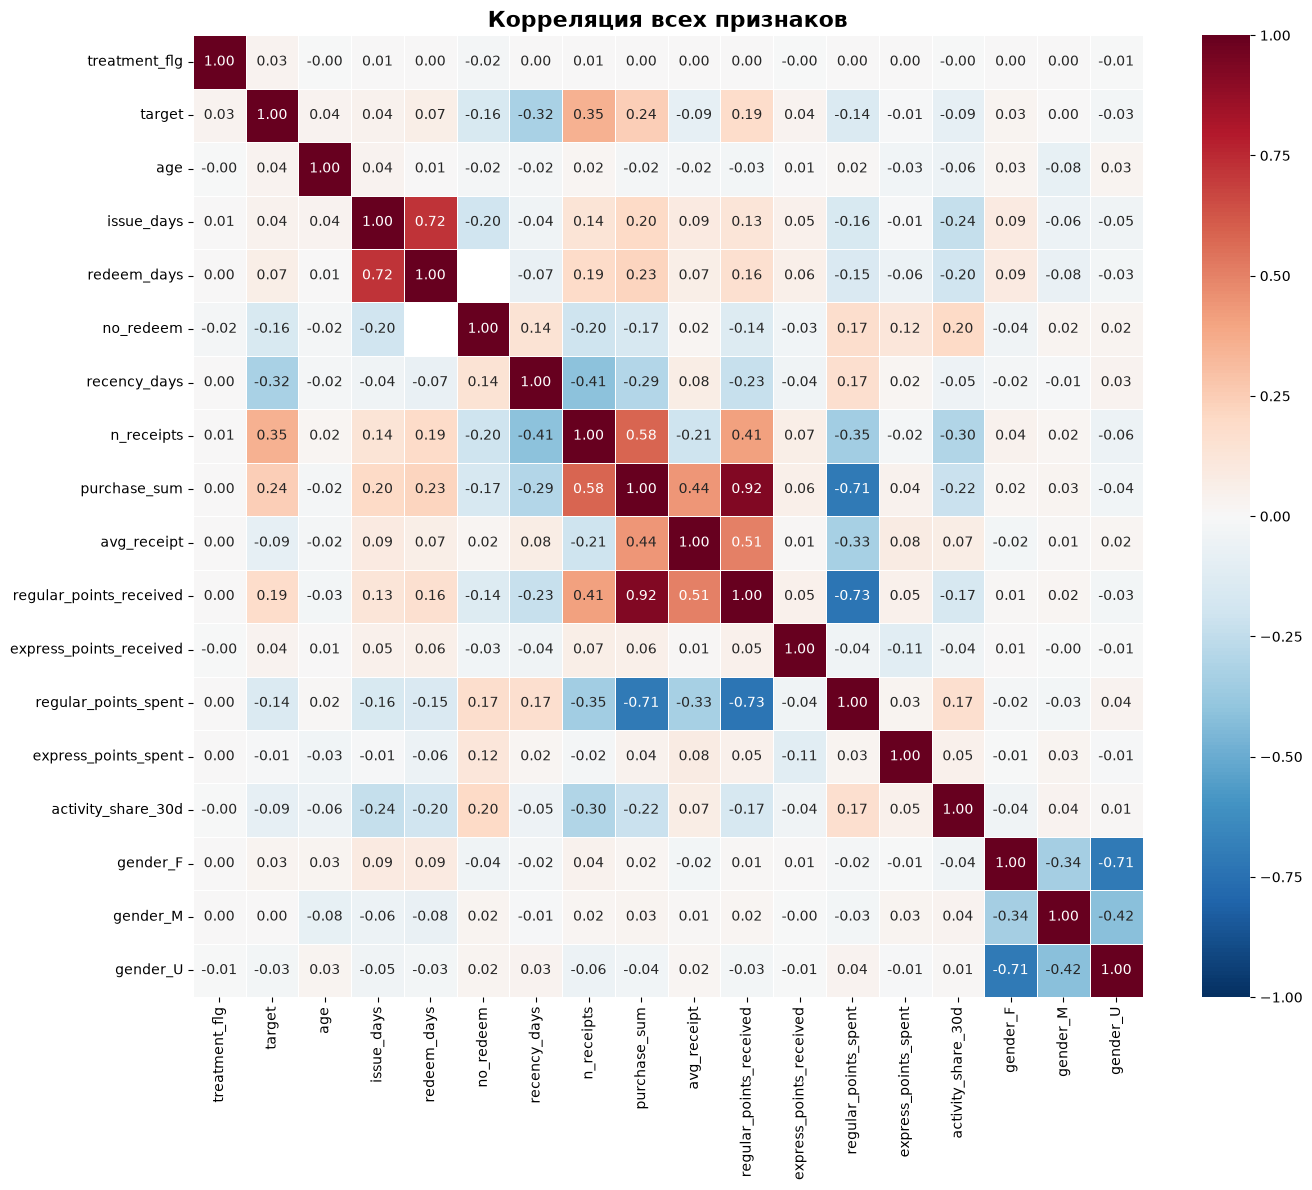

In [40]:
features_df = dataset.drop(columns=['client_id']).copy()
df_encoded = pd.get_dummies(
    features_df,
    columns=CATEGORICAL_FEATURES,
    drop_first=False,
    dtype=int,
)

corr = df_encoded.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title('Корреляция всех признаков', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


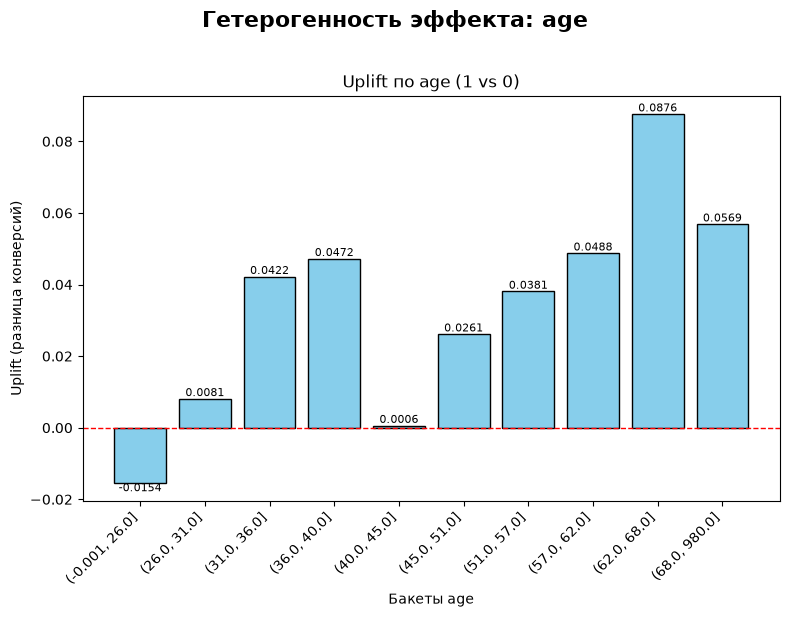

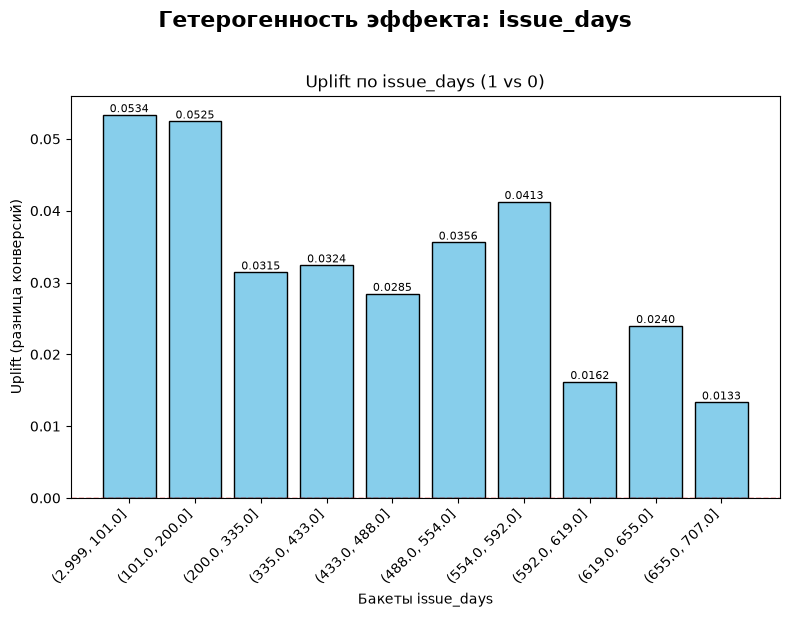

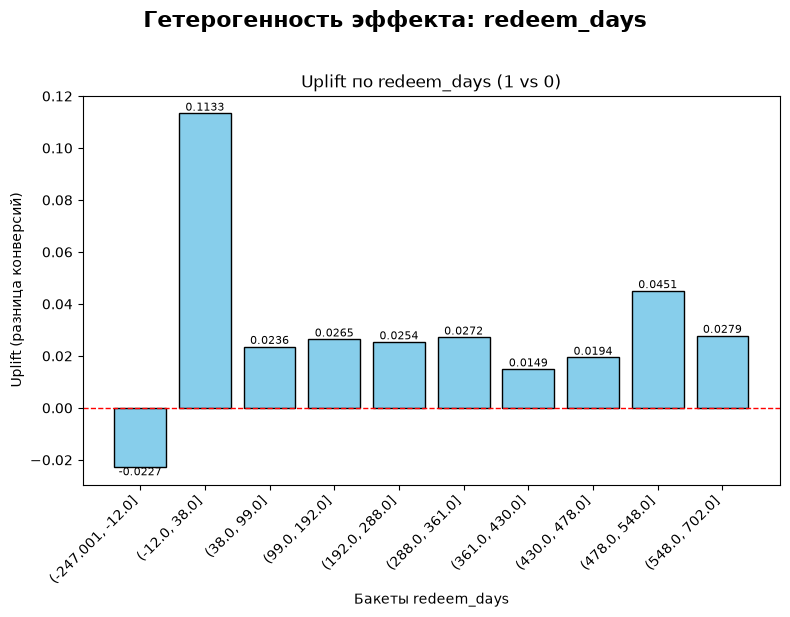

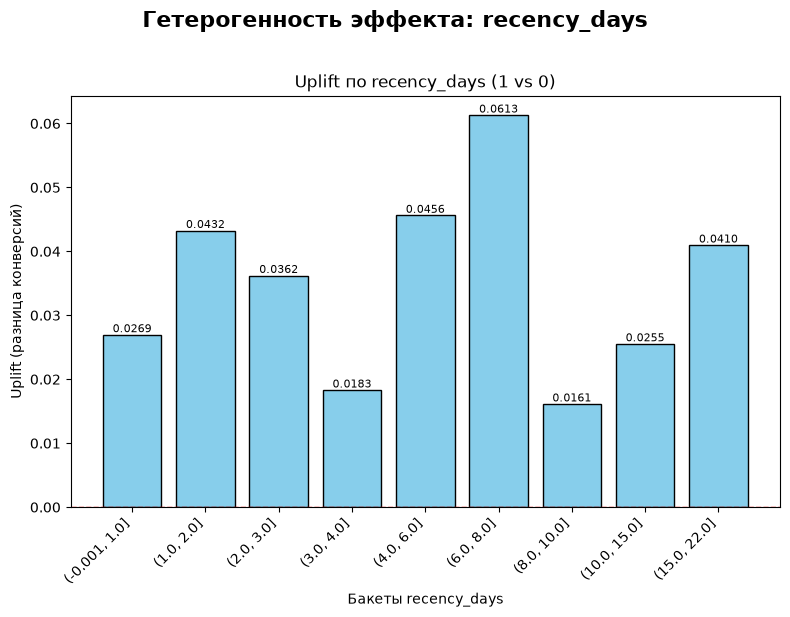

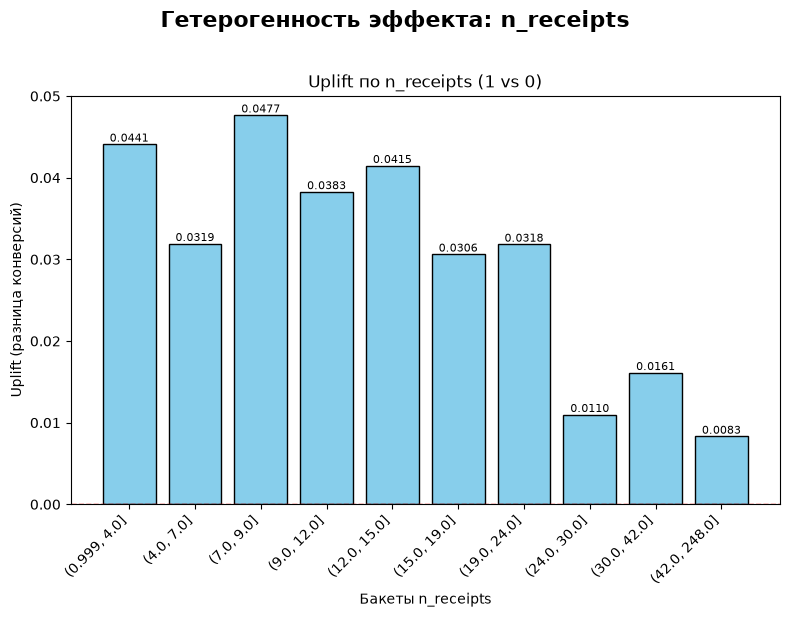

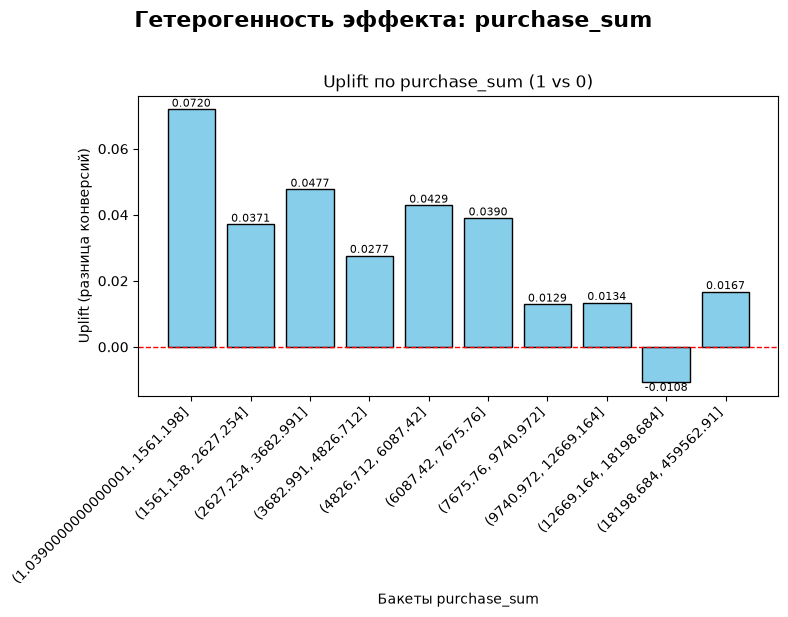

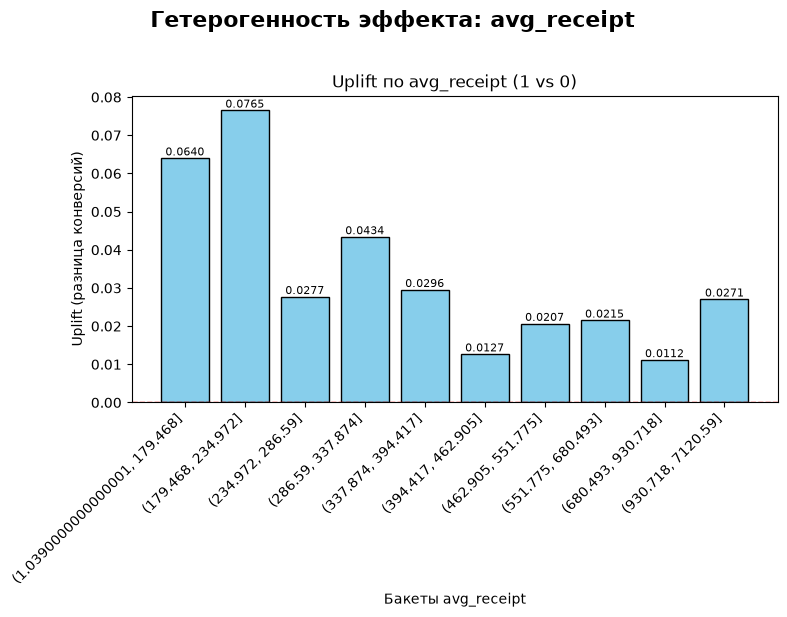

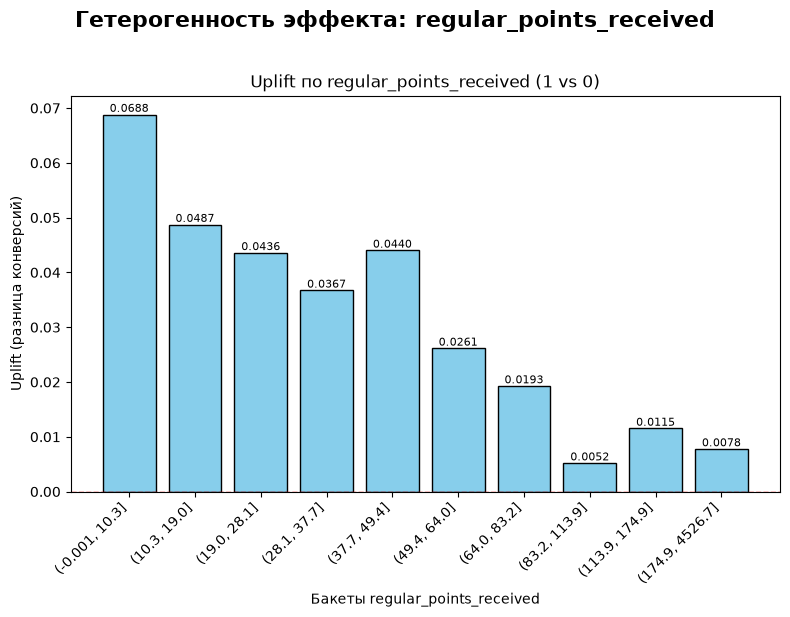

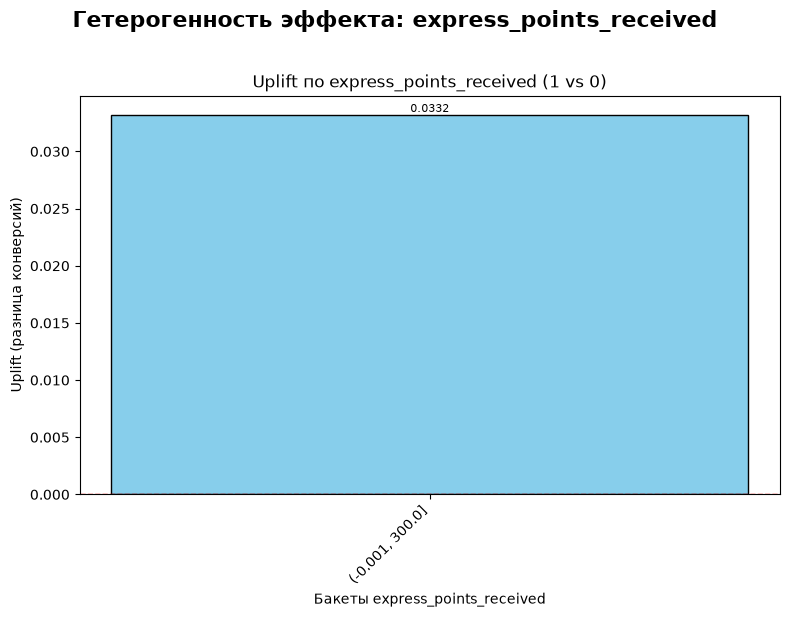

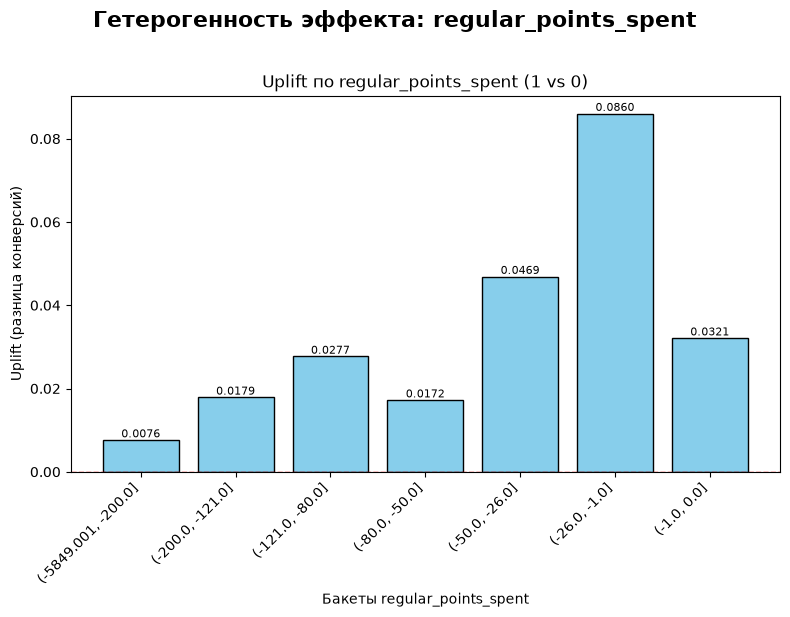

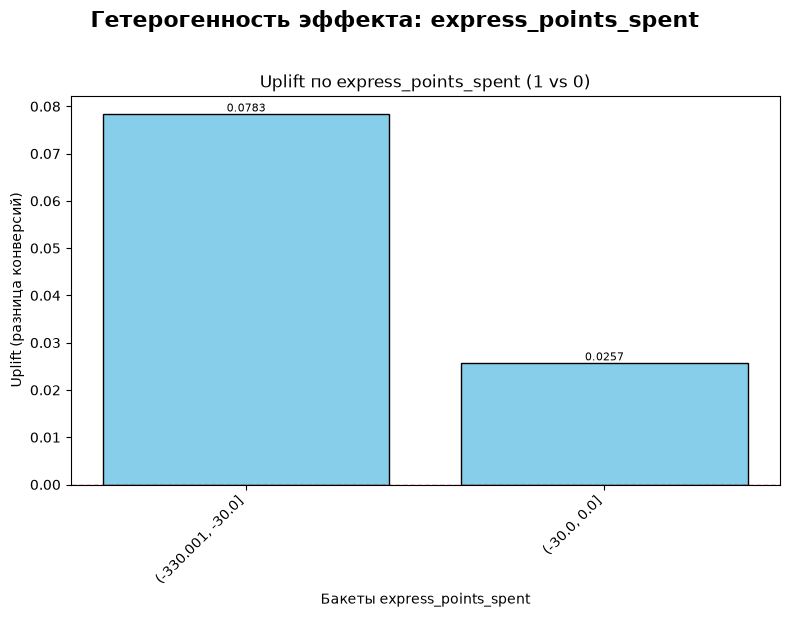

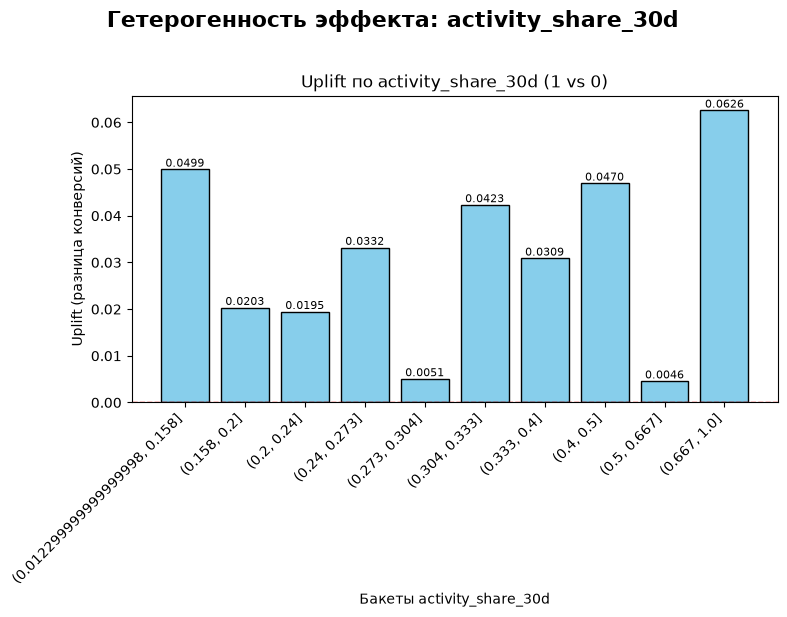

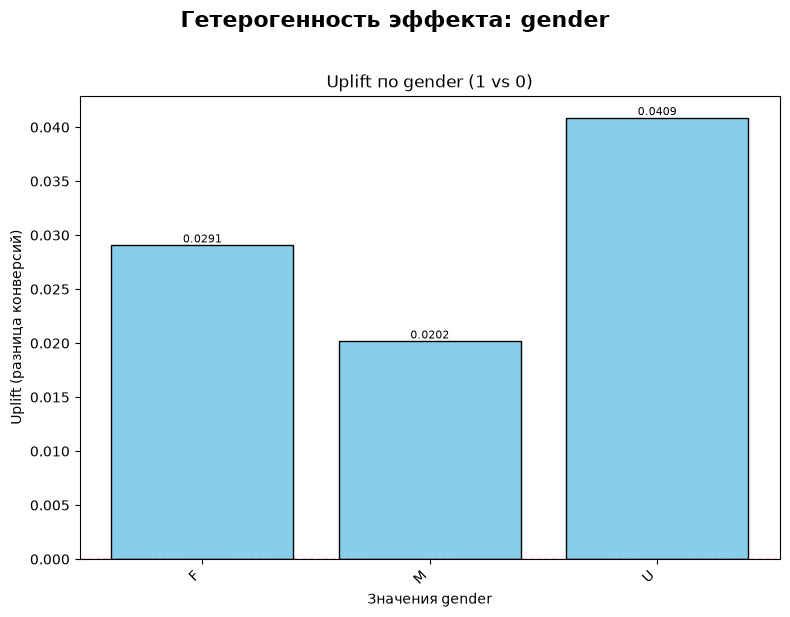

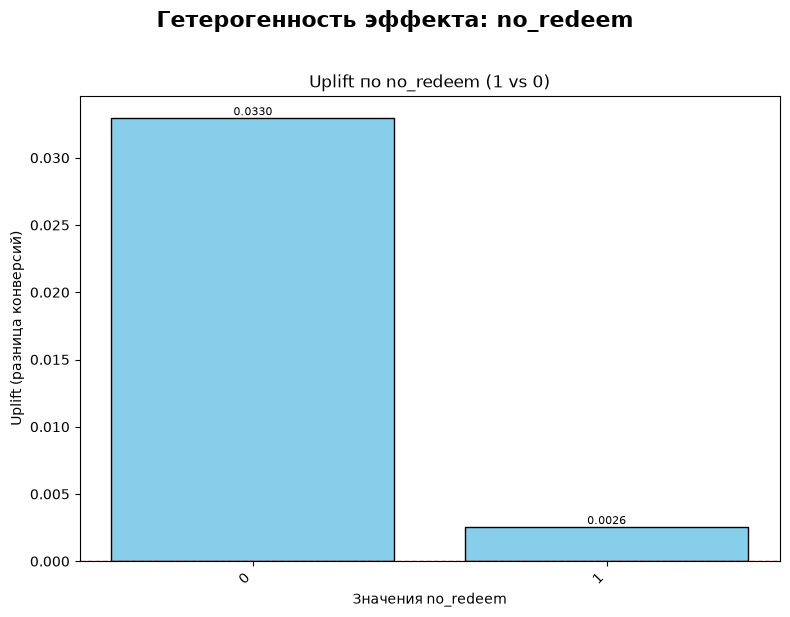

In [41]:
df_plot = dataset.copy()

# no_redeem и gender не режутся на децили: у них мало уникальных значений.
features_for_bucket = [
    'age',
    'issue_days',
    'redeem_days',
    'recency_days',
    'n_receipts',
    'purchase_sum',
    'avg_receipt',
    'regular_points_received',
    'express_points_received',
    'regular_points_spent',
    'express_points_spent',
    'activity_share_30d',
]
features_no_bucket = ['gender', 'no_redeem']

for feature in features_for_bucket + features_no_bucket:
    use_buckets = feature in features_for_bucket and df_plot[feature].nunique(dropna=True) >= 2
    if use_buckets:
        col_name = f'bucket_{feature}'
        df_plot[col_name] = pd.qcut(df_plot[feature], q=10, duplicates='drop')
        x_label = f'Бакеты {feature}'
    else:
        col_name = feature
        x_label = f'Значения {feature}'

    pivot = (
        df_plot.groupby([col_name, TREATMENT_COL], observed=False)[TARGET_COL]
        .mean()
        .unstack()
    )
    needed = set(TEST_GROUPS) | {CONTROL_NAME}
    if pivot.empty or not needed.issubset(set(pivot.columns)):
        print(f'Пропуск графика {feature}: в непустых значениях нет обеих групп')
        continue

    n_groups = len(TEST_GROUPS)
    fig, axes = plt.subplots(1, n_groups, figsize=(8 * n_groups, 6), sharey=True, squeeze=False)
    x_axis = range(len(pivot))

    for i, group in enumerate(TEST_GROUPS):
        ax = axes[0, i]
        uplift = pivot[group] - pivot[CONTROL_NAME]
        bars = ax.bar(list(x_axis), uplift, color='skyblue', edgecolor='black')
        ax.axhline(0, color='red', linestyle='--', linewidth=1)
        ax.set_xticks(list(x_axis))
        ax.set_xticklabels([str(idx) for idx in pivot.index], rotation=45, ha='right')
        ax.set_xlabel(x_label)
        if i == 0:
            ax.set_ylabel('Uplift (разница конверсий)')
        ax.set_title(f'Uplift по {feature} ({group} vs {CONTROL_NAME})')

        for bar in bars:
            yval = bar.get_height()
            if pd.isna(yval):
                continue
            va = 'bottom' if yval >= 0 else 'top'
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                yval,
                f'{yval:.4f}',
                ha='center',
                va=va,
                fontsize=8,
            )

    plt.suptitle(f'Гетерогенность эффекта: {feature}', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


**Выводы по анализу**

Считалось на 50 000 клиентах, не на всём train.

1. По одному признаку группы почти совпадают. Значим только `no_redeem`: 8.2% в тесте против 9.3% в контроле, SMD 0.038, p = 2.19e-05. Остальные SMD не выше 0.014 и незначимы. Совместно LightGBM всё же немного отделяет группы: OOF AUC 0.5203, 95% ДИ [0.5145; 0.5269] не накрывает 0.5. Назначение близко к случайному, но не идеально.

2. Эффект коммуникации есть. Конверсия 63.65% против 60.33%, абсолютный эффект +3.32 п.п., z = 7.65, p = 2.00e-14. Holm совпадает с сырым p-value, сравнение одно. На уровне 0.05 эффект значим.

3. Сильной линейной связи с `target` нет. Самые заметные корреляции: `n_receipts` 0.35, `recency_days` -0.32, `purchase_sum` 0.24, `no_redeem` -0.16. С `treatment_flg` все признаки почти не коррелируют (около 0). Между собой сильно связаны `purchase_sum` и `regular_points_received` (0.92), `purchase_sum` и `regular_points_spent` (-0.71), `issue_days` и `redeem_days` (0.72). `avg_receipt` с суммой коррелирует только на 0.44 и с числом чеков на -0.21, но по построению это сумма, делённая на число чеков.

4. Uplift по большинству бакетов положительный и того же порядка, что общий эффект около 0.03. Знак меняется мало: отрицательны только самый молодой бакет `age` (-0.015), бакет `redeem_days` с отрицательной давностью (-0.023) и один высокий бакет `purchase_sum` (-0.011). Сильнее эффект у небольших сумм и чеков, малого числа начисленных regular-баллов и у клиентов 62–68 лет (0.088). У тех, кто не списывал баллы (`no_redeem = 1`), uplift почти ноль (0.003) против 0.033 у остальных. По полу эффект везде положительный: U 0.041, F 0.029, M 0.020. `express_points_received` почти не режется на бакеты, один столбец 0.033. Списанные баллы в данных отрицательные: чем ближе `regular_points_spent` к нулю, тем uplift выше, до 0.086.

5. В бейзлайне оставить стартовый набор и нелинейную модель: с таргетом нет сильных линейных связей, а эффект по бакетам неровный.
